1.Import and load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("train.csv")
df.shape

(20640, 9)

2. Histogram of the price

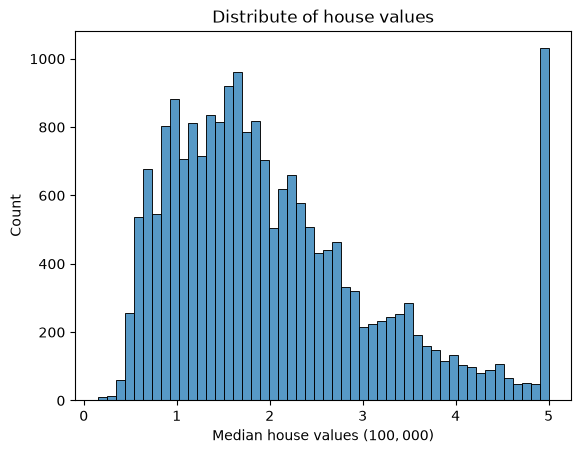

In [2]:
plt.Figure(figsize=(8,4))
sns.histplot(df["MedHouseVal"], bins=50)
plt.title("Distribute of house values")
plt.xlabel("Median house values ($100,000$)")
plt.show()

3. Correlation Table

In [3]:
df.corr()["MedHouseVal"].sort_values(ascending=False)

MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64

4. Heatmap

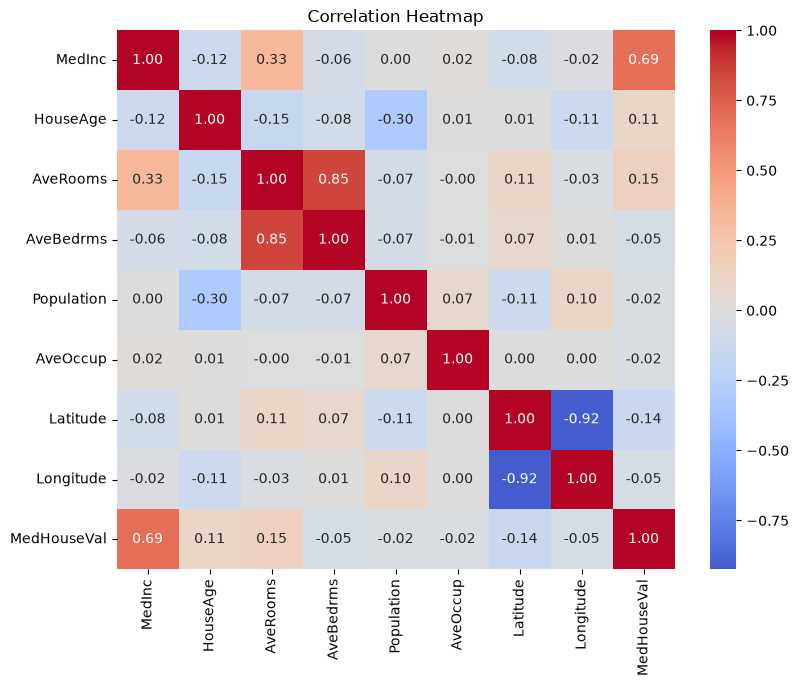

In [5]:
plt.figure(figsize=(9,7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

5. Income vs Price Scatter

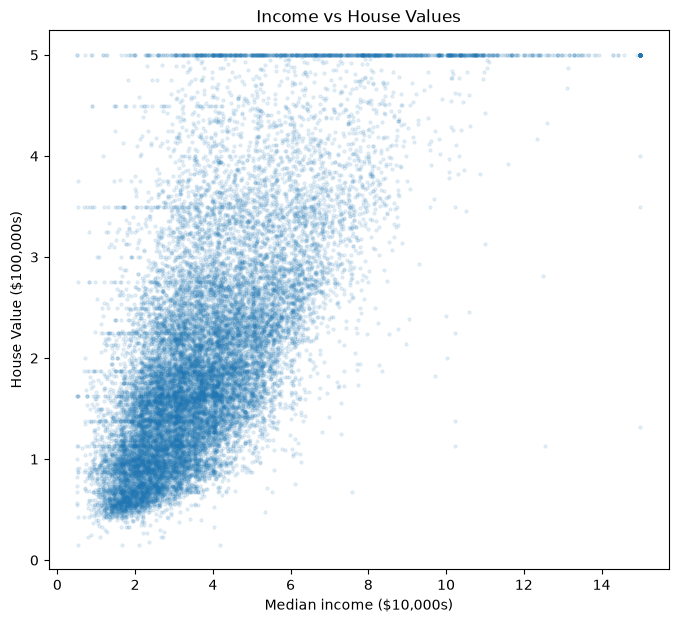

In [6]:
plt.figure(figsize=(8, 7))
plt.scatter(df["MedInc"], df["MedHouseVal"], alpha=0.1, s=5)
plt.xlabel("Median income ($10,000s)")
plt.ylabel("House Value ($100,000s)")
plt.title("Income vs House Values")
plt.show()

6.California Price Map

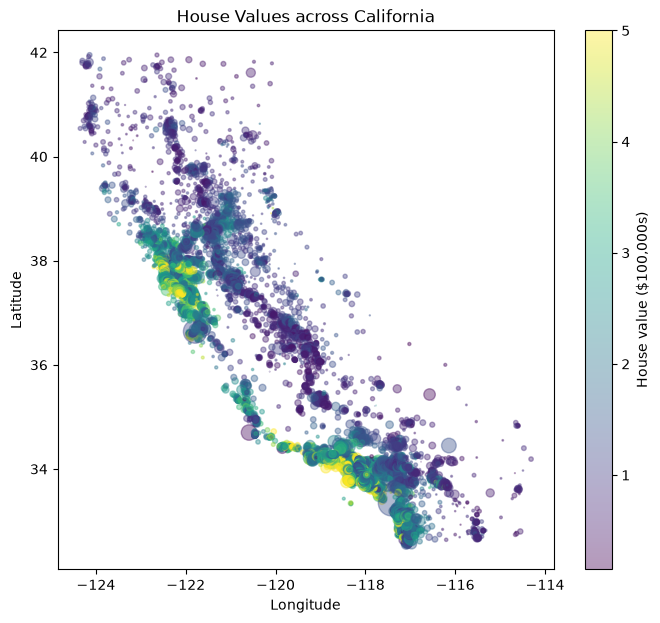

In [8]:
plt.figure(figsize=(8,7))
plt.scatter(df["Longitude"], df["Latitude"], c=df["MedHouseVal"],
            cmap="viridis", s=df["Population"] / 100, alpha=0.4)
plt.colorbar(label="House value ($100,000s)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("House Values across California")
plt.show()

7. Boxplots for outliers

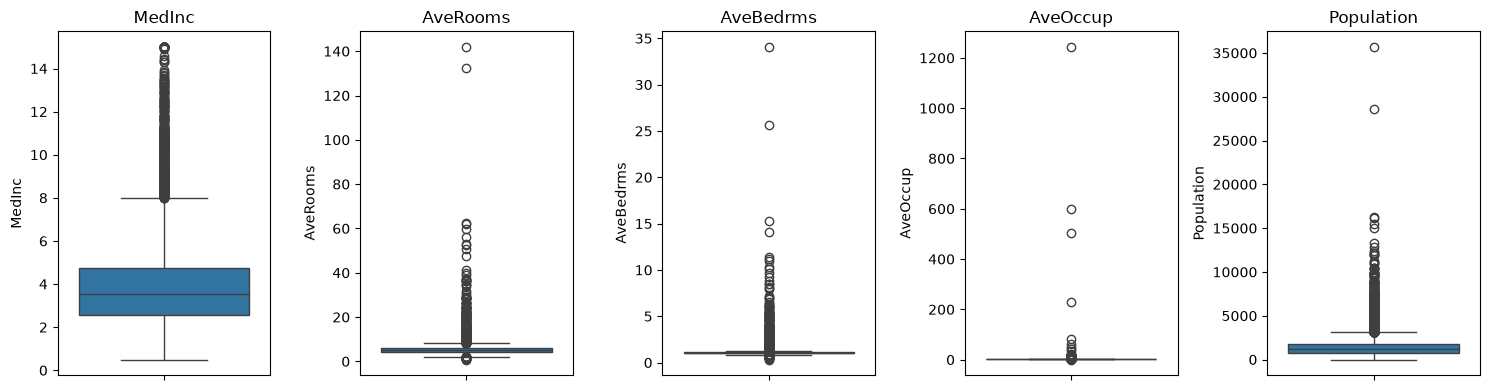

In [10]:
cols=["MedInc", "AveRooms", "AveBedrms", "AveOccup", "Population"]
fig, axes = plt.subplots(1, len(cols), figsize=(15, 4))
for ax, col in zip(axes, cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()    

8. Count the outliers and capped prices

In [11]:
for col in cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {outliers} outliers")

print("Capped prices (>= 5.0):", (df["MedHouseVal"] >= 5.0).sum())

MedInc: 681 outliers
AveRooms: 511 outliers
AveBedrms: 1424 outliers
AveOccup: 711 outliers
Population: 1196 outliers
Capped prices (>= 5.0): 992
